# Selección de cartera: CAT – MRK – MSFT
**Dataset de entrada:** `dowjones_diario_2016_2025.csv` · **Ruta:** `Datos/Transformados/dowjones_diario_2016_2025.csv`

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
import kaleido

from packages.bbva_graficos import configurar_graficos, guardar_mpl, guardar_plotly, fmt_es, BBVA, cerrar_grafico
configurar_graficos()

escala_div = LinearSegmentedColormap.from_list('bbva_div', [BBVA['marino'], BBVA['blanco'], BBVA['agua']])

ruta = 'Datos/Transformados/dowjones_diario_2016_2025.csv'
dias = 252
tasa_libre = 0.01

cartera = ['CAT', 'MRK', 'MSFT']      # el paso 7 comprueba que es la 1.ª del ranking

color_CAT = BBVA['principal']
color_MRK = BBVA['agua']
color_MSFT = BBVA['medio']
gris = BBVA['gris_dato']

fuente_texto = 'dowjones_diario_2016_2025.csv'
fuente = f'Fuente: {fuente_texto}'

excluidas = {
    'UNH': 'Eventos exógenos', 'BA': 'Eventos exógenos', 'MMM': 'Eventos exógenos', 'JNJ': 'Eventos exógenos',
    'HON': 'Eventos exógenos', 'CVX': 'Eventos exógenos', 'VZ': 'Eventos exógenos', 'AAPL': 'Eventos exógenos',
    'NVDA': 'Volatilidad excesiva', 'WMT': 'Problemas en sus datos de fechas',
}

# Sector GICS de cada acción del dataset (INTC y DOW los hemos asignado nosotros)
sector = {
    'AAPL': 'Tecnología', 'CRM': 'Tecnología', 'CSCO': 'Tecnología', 'IBM': 'Tecnología',
    'MSFT': 'Tecnología', 'INTC': 'Tecnología',
    'AXP': 'Financiero', 'GS': 'Financiero', 'JPM': 'Financiero', 'TRV': 'Financiero', 'V': 'Financiero',
    'AMGN': 'Salud', 'JNJ': 'Salud', 'MRK': 'Salud', 'UNH': 'Salud',
    'KO': 'Consumo Básico', 'PG': 'Consumo Básico',
    'HD': 'Consumo Discrecional', 'MCD': 'Consumo Discrecional', 'NKE': 'Consumo Discrecional',
    'BA': 'Industrial', 'CAT': 'Industrial', 'MMM': 'Industrial',
    'DIS': 'Comunicación',
    'CVX': 'Energía',
    'DOW': 'Materiales',
}

## Paso 1. Carga e inspección

In [2]:
datos = pd.read_csv(ruta)
datos['date'] = pd.to_datetime(datos['date'])

print('Columnas:', list(datos.columns))
print('Filas y columnas:', datos.shape)
print('Fecha inicial:', datos['date'].min())
print('Fecha final:', datos['date'].max())
print('Tickers:', sorted(datos['symbol'].unique()))
datos.head()

Columnas: ['symbol', 'date', 'open', 'high', 'low', 'close', 'volume']
Filas y columnas: (64557, 7)
Fecha inicial: 2016-01-04 00:00:00
Fecha final: 2025-12-31 00:00:00
Tickers: ['AAPL', 'AMGN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'DOW', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'PG', 'TRV', 'UNH', 'V']


,symbol,date,open,high,low,close,volume
0,AAPL,2016-01-04,25.652500,26.342501,25.500000,26.337500,270597600.0
1,AAPL,2016-01-05,26.437500,26.462500,25.602501,25.677500,223164000.0
2,AAPL,2016-01-06,25.139999,25.592501,24.967501,25.174999,273829600.0
3,AAPL,2016-01-07,24.670000,25.032499,24.107500,24.112499,324377600.0
4,AAPL,2016-01-08,24.637501,24.777500,24.190001,24.240000,283192000.0


In [3]:
filas_por_dia = datos.groupby(['symbol', 'date']).size()
print('Máximo de filas por ticker y día:', filas_por_dia.max())

resumen = datos.groupby('symbol')['date'].agg(['count', 'min', 'max'])
resumen

Máximo de filas por ticker y día: 1


,count,min,max
symbol,,,
AAPL,2514,2016-01-04,2025-12-31
AMGN,2514,2016-01-04,2025-12-31
AXP,2514,2016-01-04,2025-12-31
BA,2514,2016-01-04,2025-12-31
CAT,2514,2016-01-04,2025-12-31
CRM,2514,2016-01-04,2025-12-31
CSCO,2514,2016-01-04,2025-12-31
CVX,2514,2016-01-04,2025-12-31
DIS,2514,2016-01-04,2025-12-31


In [4]:
precios = datos.pivot(index='date', columns='symbol', values='close')
precios.head()

symbol,AAPL,AMGN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,DOW,...,KO,MCD,MMM,MRK,MSFT,NKE,PG,TRV,UNH,V
date,,,,,,,,,,,,,,,,,,,,,
2016-01-04,26.337500,158.339996,67.589996,140.500000,67.989998,76.709999,26.410000,88.849998,102.980003,NaN,...,42.400002,117.580002,122.759193,50.076336,54.799999,61.520000,78.370003,109.970001,116.459999,75.699997
2016-01-05,25.677500,158.169998,66.550003,141.070007,67.279999,77.050003,26.290001,89.610001,100.900002,NaN,...,42.549999,119.199997,123.294312,50.715649,55.049999,62.380001,78.620003,110.470001,116.680000,76.269997
2016-01-06,25.174999,156.720001,64.419998,138.830002,66.220001,76.290001,26.010000,86.070000,100.360001,NaN,...,42.320000,118.400002,120.811035,50.019085,54.049999,61.490002,77.860001,109.040001,115.489998,75.269997
2016-01-07,24.112499,152.979996,63.840000,133.009995,63.939999,74.300003,25.410000,83.019997,99.500000,NaN,...,41.619999,115.660004,117.867889,49.580154,52.169998,59.849998,77.180000,106.440002,112.089996,73.790001
2016-01-08,24.240000,150.710007,63.630001,129.990005,63.290001,73.230003,24.780001,82.129997,99.250000,NaN,...,41.509998,115.480003,117.466553,48.740459,52.330002,58.869999,75.970001,105.989998,110.160004,72.879997


Guardado: Graficos/heatmap_correlacion_todas.png


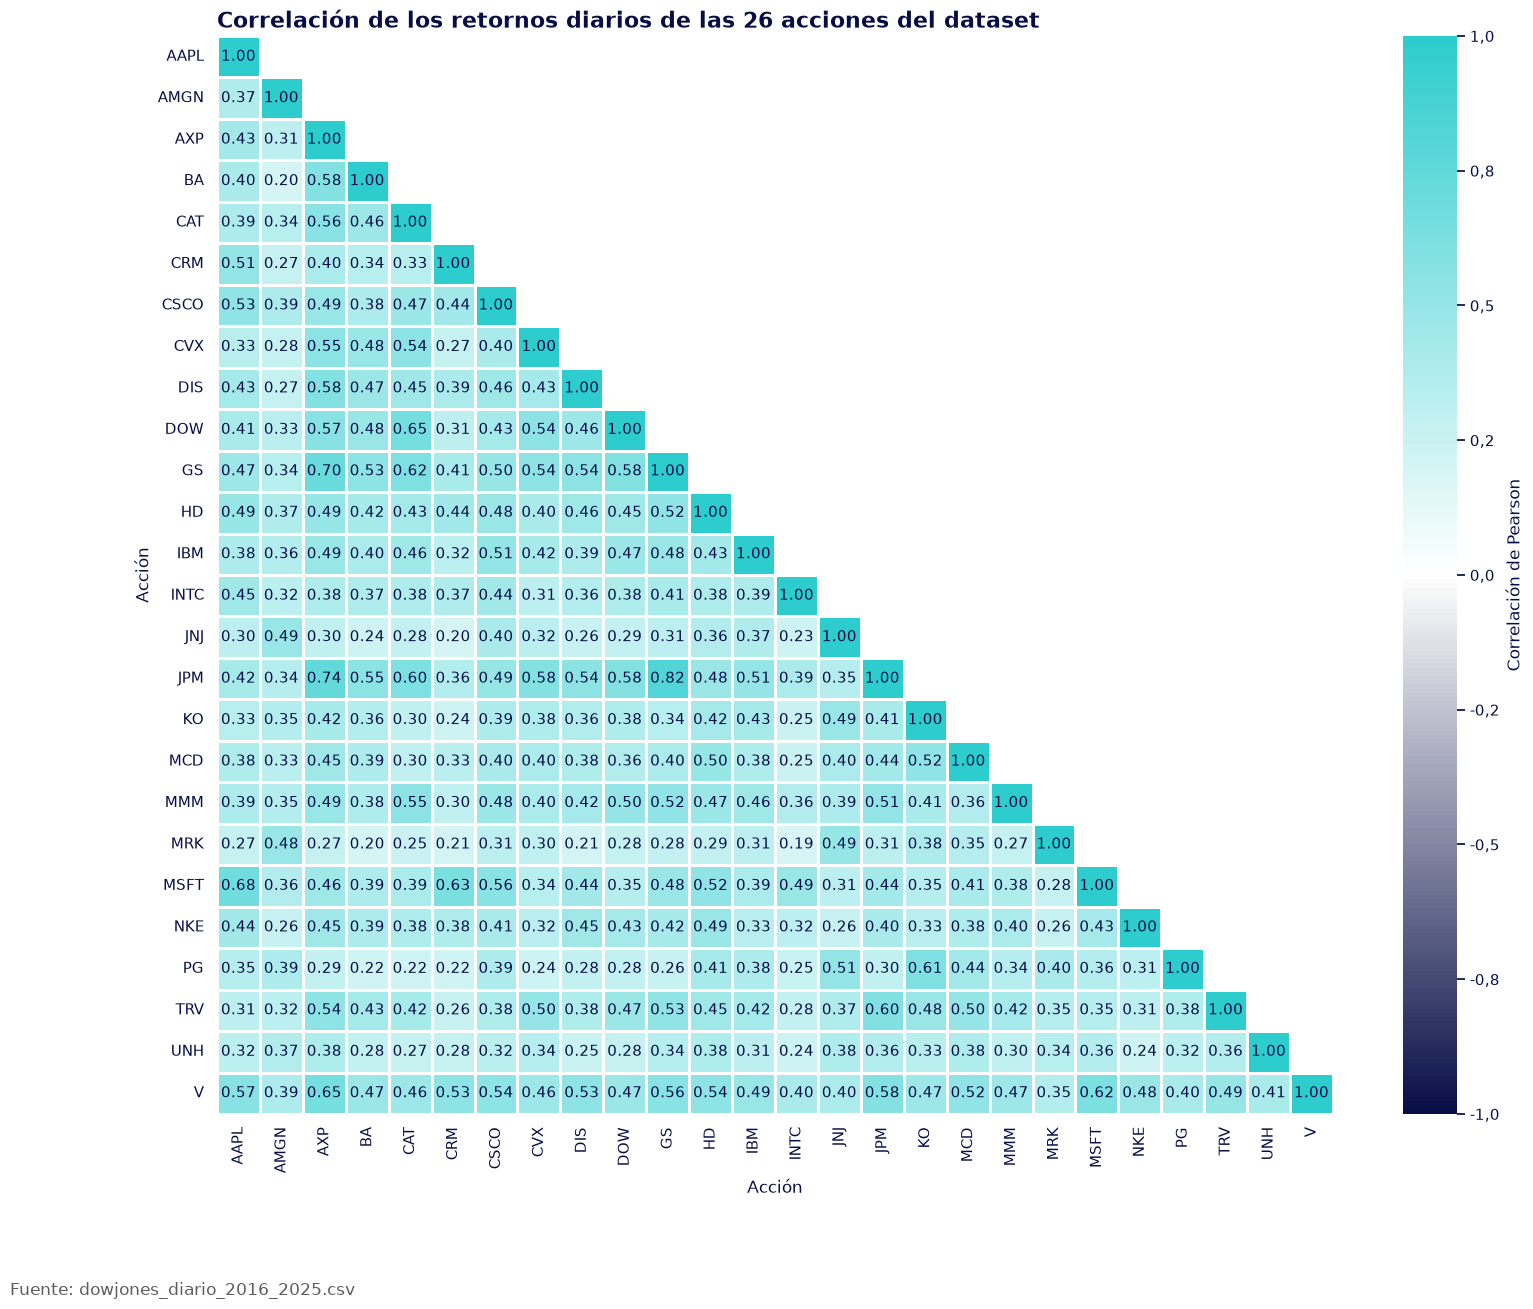

PosixPath('Graficos/heatmap_correlacion_todas.png')

In [5]:
retorno_cor = np.log(precios / precios.shift(1)).corr()
mascara_todas = np.triu(np.ones_like(retorno_cor, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(18, 14))
sns.heatmap(retorno_cor, mask=mascara_todas, annot=True, fmt='.2f', cmap=escala_div, vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor=BBVA['blanco'], annot_kws={'size': 11, 'color': BBVA['marino']},
            cbar_kws={'label': 'Correlación de Pearson'}, ax=ax)
ax.grid(False)
ax.collections[0].colorbar.ax.yaxis.set_major_formatter(lambda v, _: fmt_es(v, 1))
ax.tick_params(axis='x', labelrotation=90)
ax.set_title('Correlación de los retornos diarios de las 26 acciones del dataset')
ax.set_xlabel('Acción')
ax.set_ylabel('Acción')
cerrar_grafico(fig, 'heatmap_correlacion_todas', fuente=fuente_texto, ajustar_titulos=False)

Guardado: Graficos/precio_normalizado_cartera.png


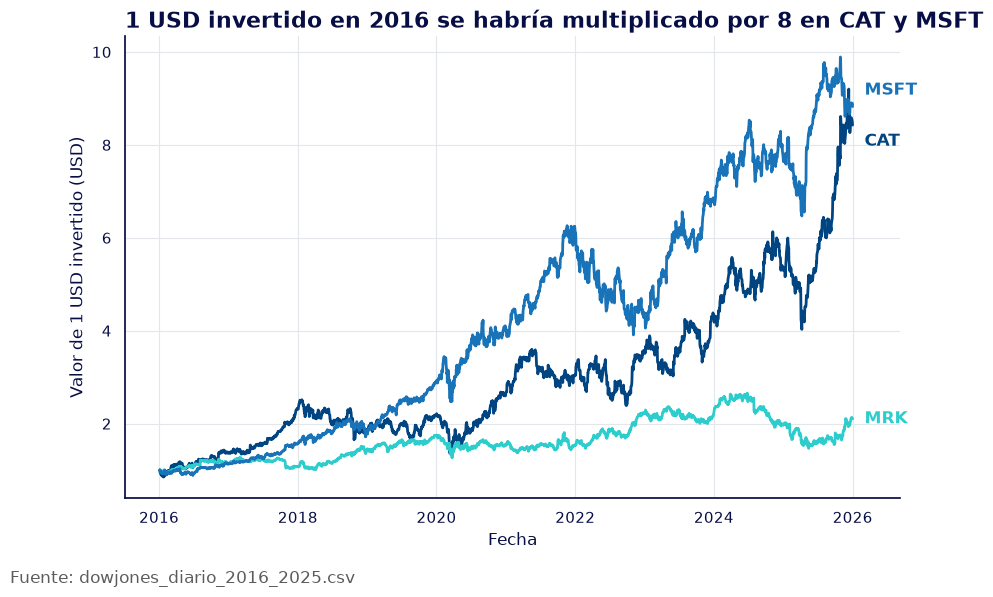

PosixPath('Graficos/precio_normalizado_cartera.png')

In [6]:
precios_norm = precios[cartera] / precios[cartera].iloc[0]

fig, ax = plt.subplots()
ax.plot(precios_norm['CAT'], color=color_CAT, linewidth=2)
ax.plot(precios_norm['MRK'], color=color_MRK, linewidth=2)
ax.plot(precios_norm['MSFT'], color=color_MSFT, linewidth=2)

ultima_fecha = precios_norm.index[-1]
ax.text(ultima_fecha, precios_norm['CAT'].iloc[-1] - 0.35, '  CAT', color=color_CAT, fontweight='bold', fontsize=12, va='center')
ax.text(ultima_fecha, precios_norm['MRK'].iloc[-1], '  MRK', color=color_MRK, fontweight='bold', fontsize=12, va='center')
ax.text(ultima_fecha, precios_norm['MSFT'].iloc[-1] + 0.35, '  MSFT', color=color_MSFT, fontweight='bold', fontsize=12, va='center')
ax.set_xlim(right=ultima_fecha + pd.Timedelta(days=250))

ax.set_title('1 USD invertido en 2016 se habría multiplicado por 8 en CAT y MSFT')
ax.set_xlabel('Fecha')
ax.set_ylabel('Valor de 1 USD invertido (USD)')
ax.yaxis.set_major_formatter(lambda v, _: fmt_es(v))
cerrar_grafico(fig, 'precio_normalizado_cartera', fuente=fuente_texto, ajustar_titulos=False)

In [7]:
precios_norm = precios[cartera] / precios[cartera].iloc[0]
colores = {'CAT': color_CAT, 'MRK': color_MRK, 'MSFT': color_MSFT}

fig = go.Figure()
for t in cartera:
    fig.add_trace(go.Scatter(x=precios_norm.index, y=precios_norm[t], mode='lines', name=t,
                             line=dict(color=colores[t], width=2),
                             hovertemplate=t + ': %{y:,.2f} USD<extra></extra>'))
fig.update_layout(title='1 USD invertido en 2016 se habría multiplicado por 8 en CAT y MSFT',
                  xaxis_title='Fecha', yaxis_title='Valor de 1 USD invertido (USD)',
                  hovermode='x unified', separators=',.', xaxis=dict(hoverformat='%d %b %Y'),
                  legend=dict(title='Acción'))
fig.update_layout(margin=dict(b=120), legend=dict(x=1, xanchor='right', y=1.02, yanchor='bottom'))
fig.add_annotation(text=fuente, xref='paper', yref='paper', x=0, y=-0.2, showarrow=False, font=dict(size=11))
guardar_plotly(fig, 'precio_normalizado_cartera_interactivo')
fig.show(config={'displaylogo': False})

Guardado: Graficos/precio_normalizado_cartera_interactivo.png


## Paso 2. Retornos logarítmicos

In [8]:
retornos = np.log(precios / precios.shift(1))
retornos = retornos.dropna(how='all')     # quita la primera fila, que no tiene día anterior
retornos[cartera].describe()

symbol,CAT,MRK,MSFT
count,2513.000000,2513.000000,2513.000000
mean,0.000848,0.000296,0.000867
std,0.019178,0.014275,0.016855
min,-0.153430,-0.103840,-0.159453
25%,-0.008641,-0.006589,-0.006750
50%,0.000743,0.000266,0.000982
75%,0.011043,0.007580,0.009545
max,0.110061,0.099013,0.132929


Guardado: Graficos/histograma_retornos_cartera.png


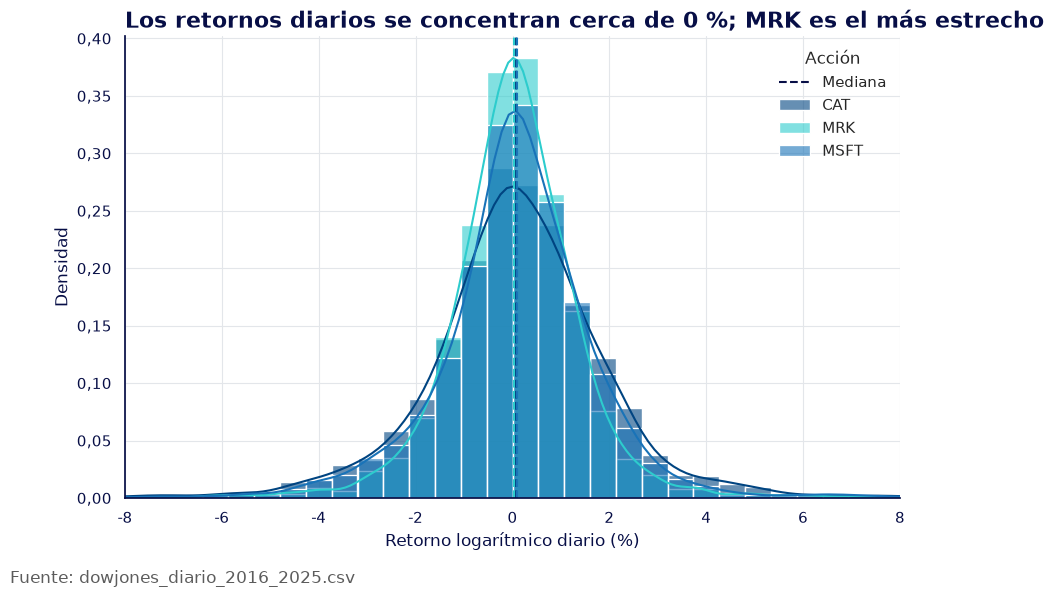

PosixPath('Graficos/histograma_retornos_cartera.png')

In [9]:
fig, ax = plt.subplots()
# 30 bins; limitamos el eje a ±8 % (los días con retornos más extremos son muy pocos)
sns.histplot(retornos['CAT'] * 100, bins=30, binrange=(-8, 8), kde=True, stat='density', color=color_CAT, alpha=0.6, label='CAT', ax=ax)
sns.histplot(retornos['MRK'] * 100, bins=30, binrange=(-8, 8), kde=True, stat='density', color=color_MRK, alpha=0.6, label='MRK', ax=ax)
sns.histplot(retornos['MSFT'] * 100, bins=30, binrange=(-8, 8), kde=True, stat='density', color=color_MSFT, alpha=0.6, label='MSFT', ax=ax)

ax.axvline(retornos['CAT'].median() * 100, color=color_CAT, linestyle='--', linewidth=1.5)
ax.axvline(retornos['MRK'].median() * 100, color=color_MRK, linestyle='--', linewidth=1.5)
ax.axvline(retornos['MSFT'].median() * 100, color=color_MSFT, linestyle='--', linewidth=1.5)
ax.plot([], [], color=BBVA['marino'], linestyle='--', label='Mediana')

ax.set_xlim(-8, 8)
ax.set_title('Los retornos diarios se concentran cerca de 0 %; MRK es el más estrecho')
ax.set_xlabel('Retorno logarítmico diario (%)')
ax.set_ylabel('Densidad')
ax.xaxis.set_major_formatter(lambda v, _: fmt_es(v))
ax.yaxis.set_major_formatter(lambda v, _: fmt_es(v, 2))
ax.legend(title='Acción')
cerrar_grafico(fig, 'histograma_retornos_cartera', fuente=fuente_texto, ajustar_titulos=False)

## Paso 3. Criterios C1–C3 para todas las acciones

In [10]:
mu = dias * retornos.mean()
sigma = np.sqrt(dias) * retornos.std()
sharpe = (mu - tasa_libre) / sigma

metricas = pd.DataFrame()
metricas['mu'] = mu
metricas['sigma'] = sigma
metricas['sharpe'] = sharpe
metricas['sesiones'] = retornos.count()
metricas['sector'] = metricas.index.map(sector)

corr_abs = retornos.corr().abs()
n_acciones = len(corr_abs)
metricas['corr_media'] = (corr_abs.sum() - 1) / (n_acciones - 1)
metricas['corr_max'] = (corr_abs - np.eye(n_acciones)).max()

metricas['excluida'] = metricas.index.isin(list(excluidas))
metricas['motivo_exclusion'] = metricas.index.map(excluidas).fillna('')
metricas['serie_completa'] = metricas['sesiones'] == metricas['sesiones'].max()
metricas['C1_ok'] = metricas['mu'] > 0
metricas['C3_ok'] = metricas['sharpe'] > 0
metricas['elegible'] = ~metricas['excluida'] & metricas['serie_completa'] & metricas['C1_ok'] & metricas['C3_ok']
metricas['en_cartera'] = metricas.index.isin(cartera)
metricas = metricas.sort_values('sharpe', ascending=False)

metricas.to_csv('outputs/metricas_acciones.csv', index_label='ticker')
metricas.round(3)

,mu,sigma,sharpe,sesiones,sector,corr_media,corr_max,excluida,motivo_exclusion,serie_completa,C1_ok,C3_ok,elegible,en_cartera
symbol,,,,,,,,,,,,,,
MSFT,0.218,0.268,0.779,2513,Tecnología,0.430,0.676,False,,True,True,True,True,True
AAPL,0.234,0.290,0.772,2513,Tecnología,0.414,0.676,True,Eventos exógenos,True,True,True,False,False
CAT,0.214,0.304,0.669,2513,Industrial,0.420,0.649,False,,True,True,True,True,True
V,0.154,0.245,0.587,2513,Financiero,0.490,0.649,False,,True,True,True,True,False
JPM,0.163,0.276,0.553,2513,Financiero,0.484,0.823,False,,True,True,True,True,False
AXP,0.170,0.315,0.510,2513,Financiero,0.478,0.739,False,,True,True,True,True,False
GS,0.161,0.296,0.509,2513,Financiero,0.477,0.823,False,,True,True,True,True,False
MCD,0.096,0.204,0.421,2513,Consumo Discrecional,0.396,0.518,False,,True,True,True,True,False
CSCO,0.107,0.252,0.386,2513,Tecnología,0.439,0.562,False,,True,True,True,True,False


Guardado: Graficos/ranking_sharpe.png


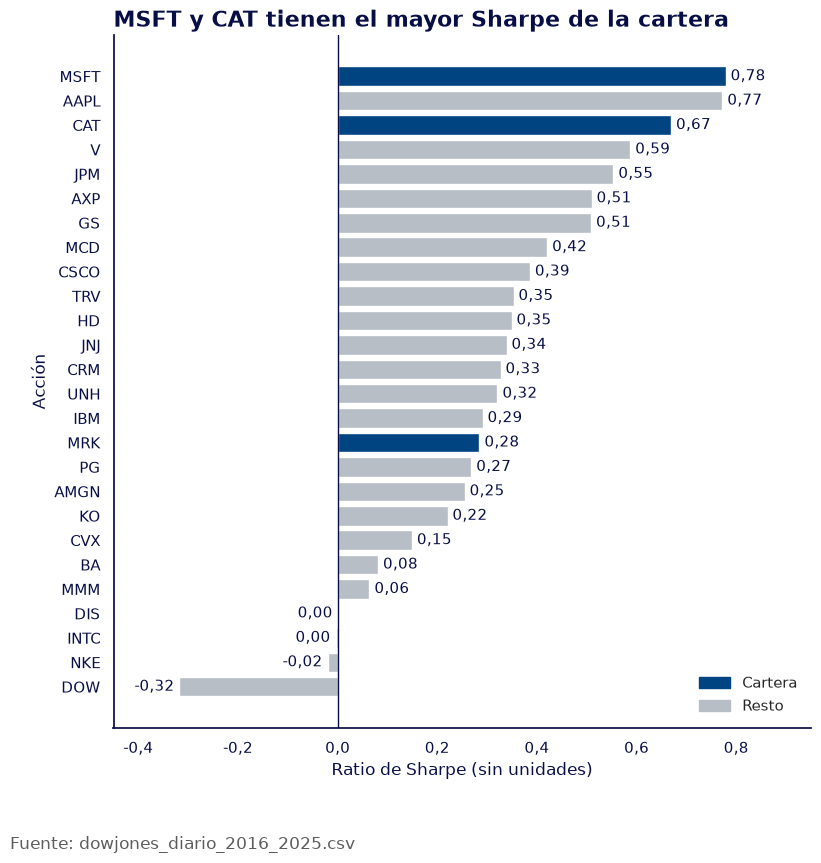

PosixPath('Graficos/ranking_sharpe.png')

In [11]:
orden = metricas.sort_values('sharpe')

colores_barras = []
for ticker in orden.index:
    if ticker in cartera:
        colores_barras.append(BBVA['principal'])
    else:
        colores_barras.append(gris)

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(orden.index, orden['sharpe'], color=colores_barras)
ax.axvline(0, color=BBVA['marino'], linewidth=1)
ax.grid(False)

for i in range(len(orden)):
    valor = orden['sharpe'].iloc[i]
    texto = fmt_es(round(valor, 2) + 0.0, 2)      # +0.0 evita que salga '-0,00'
    if valor >= 0:
        ax.text(valor + 0.01, i, texto, va='center', fontsize=11, color=BBVA['marino'])
    else:
        ax.text(valor - 0.01, i, texto, va='center', ha='right', fontsize=11, color=BBVA['marino'])

ax.set_xlim(-0.45, 0.95)
ax.set_title('MSFT y CAT tienen el mayor Sharpe de la cartera')
ax.set_xlabel('Ratio de Sharpe (sin unidades)')
ax.set_ylabel('Acción')
ax.xaxis.set_major_formatter(lambda v, _: fmt_es(v, 1))
ax.legend(handles=[Patch(color=BBVA['principal'], label='Cartera'), Patch(color=gris, label='Resto')], loc='lower right')
cerrar_grafico(fig, 'ranking_sharpe', fuente=fuente_texto, ajustar_titulos=False)

In [12]:
tabla = metricas.reset_index()
tabla['mu_pct'] = tabla['mu'] * 100
tabla['sigma_pct'] = tabla['sigma'] * 100

tabla['etiqueta'] = ''
tabla.loc[tabla['symbol'].isin(cartera), 'etiqueta'] = tabla['symbol']

grafico = go.Figure(go.Scatter(
    x=tabla['sigma_pct'], y=tabla['mu_pct'],
    mode='markers+text', text=tabla['etiqueta'], textposition='top center',
    textfont=dict(size=14, color=BBVA['marino']),
    hovertext=tabla['symbol'],
    marker=dict(size=13, opacity=0.85, color=tabla['sharpe'],
                colorscale=[[0, BBVA['gris']], [1, BBVA['principal']]],
                line=dict(width=1, color=BBVA['marino']),
                colorbar=dict(title='Sharpe')),
    hovertemplate='<b>%{hovertext}</b><br>Volatilidad: %{x:.1f} %<br>Rentabilidad: %{y:.1f} %<br>Sharpe: %{marker.color:.2f}<extra></extra>',
))
grafico.update_layout(
    title=dict(text='MSFT, AAPL y CAT ofrecen la mejor rentabilidad por unidad de riesgo', x=0.01),
    margin=dict(l=70, r=30, t=80, b=130),
    xaxis_title='Volatilidad anual σ (%)', yaxis_title='Rentabilidad anual μ (%)',
    separators=',.',
)
grafico.add_annotation(text=fuente, xref='paper', yref='paper', x=0, y=-0.22, showarrow=False, font=dict(size=12))
guardar_plotly(grafico, 'mapa_riesgo_rentabilidad')
grafico.show(config={'displaylogo': False})

Guardado: Graficos/mapa_riesgo_rentabilidad.png


## Paso 4. C4 — Correlaciones

Guardado: Graficos/heatmap_correlacion_cartera.png


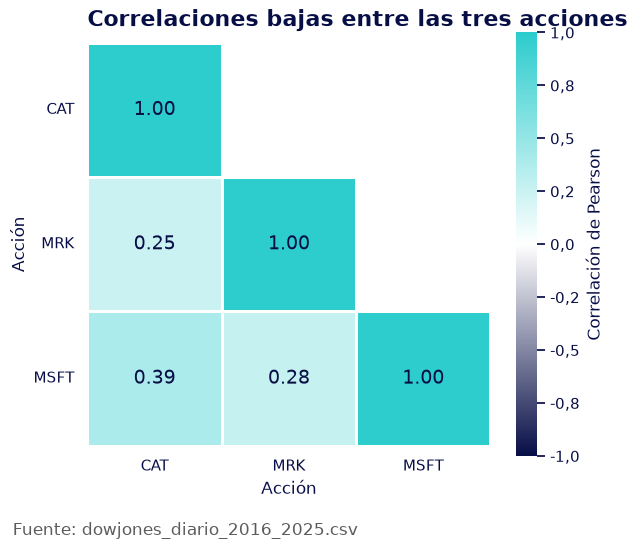

symbol,CAT,MRK,MSFT
symbol,,,
CAT,1.000,0.250,0.395
MRK,0.250,1.000,0.277
MSFT,0.395,0.277,1.000


In [13]:
correlacion = retornos[cartera].corr()
correlacion.to_csv('outputs/correlaciones_cartera.csv')

mascara = np.triu(np.ones_like(correlacion, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(correlacion, mask=mascara, annot=True, fmt='.2f', cmap=escala_div, vmin=-1, vmax=1, center=0,
            square=True, linewidths=2, linecolor=BBVA['blanco'], annot_kws={'size': 14, 'color': BBVA['marino']},
            cbar_kws={'label': 'Correlación de Pearson'}, ax=ax)
ax.grid(False)
ax.collections[0].colorbar.ax.yaxis.set_major_formatter(lambda v, _: fmt_es(v, 1))
ax.tick_params(axis='y', labelrotation=0)
ax.set_title('Correlaciones bajas entre las tres acciones', pad=12)
ax.set_xlabel('Acción')
ax.set_ylabel('Acción')
cerrar_grafico(fig, 'heatmap_correlacion_cartera', fuente=fuente_texto, ajustar_titulos=False)
correlacion.round(3)

## Paso 5. Estabilidad

Guardado: Graficos/correlacion_movil_cartera.png


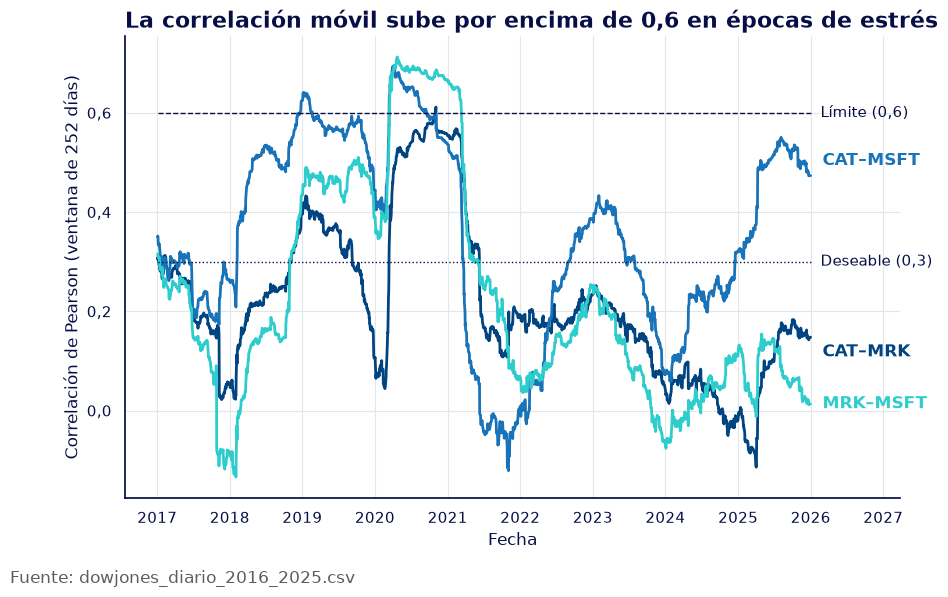

Máximo CAT-MRK: 0.612
Máximo CAT-MSFT: 0.695
Máximo MRK-MSFT: 0.713


In [14]:
corr_CAT_MRK = retornos['CAT'].rolling(dias).corr(retornos['MRK'])
corr_CAT_MSFT = retornos['CAT'].rolling(dias).corr(retornos['MSFT'])
corr_MRK_MSFT = retornos['MRK'].rolling(dias).corr(retornos['MSFT'])

fig, ax = plt.subplots()
ax.plot(corr_CAT_MRK, color=BBVA['principal'], linewidth=2)
ax.plot(corr_CAT_MSFT, color=BBVA['medio'], linewidth=2)
ax.plot(corr_MRK_MSFT, color=BBVA['agua'], linewidth=2)


ultima_fecha = corr_CAT_MRK.index[-1]
primera_fecha = corr_CAT_MRK.dropna().index[0]
ax.hlines(0.3, primera_fecha, ultima_fecha, color=BBVA['marino'], linestyle=':', linewidth=1)
ax.hlines(0.6, primera_fecha, ultima_fecha, color=BBVA['marino'], linestyle='--', linewidth=1)
ax.text(ultima_fecha, corr_CAT_MRK.iloc[-1] - 0.03, '  CAT–MRK', color=BBVA['principal'], fontweight='bold', fontsize=12, va='center')
ax.text(ultima_fecha, corr_CAT_MSFT.iloc[-1] + 0.03, '  CAT–MSFT', color=BBVA['medio'], fontweight='bold', fontsize=12, va='center')
ax.text(ultima_fecha, corr_MRK_MSFT.iloc[-1], '  MRK–MSFT', color=BBVA['agua'], fontweight='bold', fontsize=12, va='center')
ax.text(ultima_fecha, 0.3, '  Deseable (0,3)', fontsize=11, color=BBVA['marino'], va='center')
ax.text(ultima_fecha, 0.6, '  Límite (0,6)', fontsize=11, color=BBVA['marino'], va='center')
ax.set_xlim(right=ultima_fecha + pd.Timedelta(days=450))

ax.set_title('La correlación móvil sube por encima de 0,6 en épocas de estrés')
ax.set_xlabel('Fecha')
ax.set_ylabel('Correlación de Pearson (ventana de 252 días)')
ax.yaxis.set_major_formatter(lambda v, _: fmt_es(v, 1))
cerrar_grafico(fig, 'correlacion_movil_cartera', fuente=fuente_texto, ajustar_titulos=False)

print('Máximo CAT-MRK:', round(corr_CAT_MRK.max(), 3))
print('Máximo CAT-MSFT:', round(corr_CAT_MSFT.max(), 3))
print('Máximo MRK-MSFT:', round(corr_MRK_MSFT.max(), 3))

In [15]:
pares = {'CAT–MRK': (corr_CAT_MRK, BBVA['principal']),
         'CAT–MSFT': (corr_CAT_MSFT, BBVA['medio']),
         'MRK–MSFT': (corr_MRK_MSFT, BBVA['agua'])}

fig = go.Figure()
for nombre, (serie, color) in pares.items():
    fig.add_trace(go.Scatter(x=serie.index, y=serie, mode='lines', name=nombre,
                             line=dict(color=color, width=2),
                             hovertemplate=nombre + ': %{y:,.2f}<extra></extra>'))
fig.add_hline(y=0.3, line=dict(color=BBVA['marino'], dash='dot', width=1),
              annotation_text='Deseable (0,3)', annotation_position='bottom right')
fig.add_hline(y=0.6, line=dict(color=BBVA['marino'], dash='dash', width=1),
              annotation_text='Límite (0,6)', annotation_position='top right')
fig.update_layout(title='La correlación móvil sube por encima de 0,6 en épocas de estrés',
                  xaxis_title='Fecha', yaxis_title='Correlación de Pearson (ventana de 252 días)',
                  hovermode='x unified', separators=',.', xaxis=dict(hoverformat='%d %b %Y'),
                  legend=dict(title='Par'))
fig.update_layout(margin=dict(b=120), legend=dict(x=1, xanchor='right', y=1.02, yanchor='bottom'))
fig.add_annotation(text=fuente, xref='paper', yref='paper', x=0, y=-0.2, showarrow=False, font=dict(size=11))
guardar_plotly(fig, 'correlacion_movil_cartera_interactivo')
fig.show(config={'displaylogo': False})

Guardado: Graficos/correlacion_movil_cartera_interactivo.png


Guardado: Graficos/volatilidad_movil_cartera.png


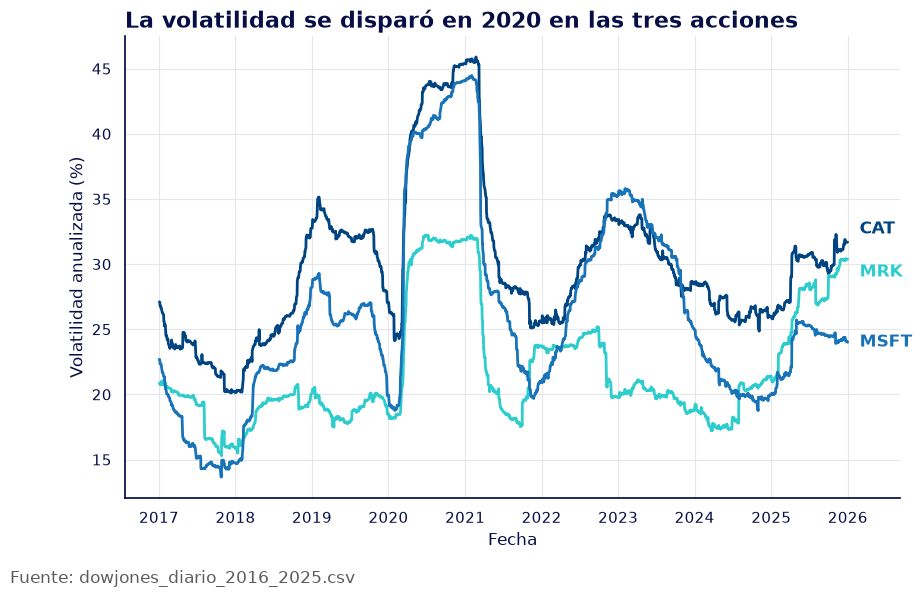

PosixPath('Graficos/volatilidad_movil_cartera.png')

In [16]:
vol_movil = retornos[cartera].rolling(dias).std() * np.sqrt(dias) * 100

fig, ax = plt.subplots()
ax.plot(vol_movil['CAT'], color=color_CAT, linewidth=2)
ax.plot(vol_movil['MRK'], color=color_MRK, linewidth=2)
ax.plot(vol_movil['MSFT'], color=color_MSFT, linewidth=2)

ultima_fecha = vol_movil.index[-1]
ax.text(ultima_fecha, vol_movil['CAT'].iloc[-1] + 1, '  CAT', color=color_CAT, fontweight='bold', fontsize=12, va='center')
ax.text(ultima_fecha, vol_movil['MRK'].iloc[-1] - 1, '  MRK', color=color_MRK, fontweight='bold', fontsize=12, va='center')
ax.text(ultima_fecha, vol_movil['MSFT'].iloc[-1], '  MSFT', color=color_MSFT, fontweight='bold', fontsize=12, va='center')
ax.set_xlim(right=ultima_fecha + pd.Timedelta(days=250))

ax.set_title('La volatilidad se disparó en 2020 en las tres acciones')
ax.set_xlabel('Fecha')
ax.set_ylabel('Volatilidad anualizada (%)')
ax.yaxis.set_major_formatter(lambda v, _: fmt_es(v))
cerrar_grafico(fig, 'volatilidad_movil_cartera', fuente=fuente_texto, ajustar_titulos=False)

In [17]:
fig = go.Figure()
for t in cartera:
    fig.add_trace(go.Scatter(x=vol_movil.index, y=vol_movil[t], mode='lines', name=t,
                             line=dict(color=colores[t], width=2),
                             hovertemplate=t + ': %{y:,.1f} %<extra></extra>'))
fig.update_layout(title='La volatilidad se disparó en 2020 en las tres acciones',
                  xaxis_title='Fecha', yaxis_title='Volatilidad anualizada (%)',
                  hovermode='x unified', separators=',.', xaxis=dict(hoverformat='%d %b %Y'),
                  legend=dict(title='Acción'))
fig.update_layout(margin=dict(b=120), legend=dict(x=1, xanchor='right', y=1.02, yanchor='bottom'))
fig.add_annotation(text=fuente, xref='paper', yref='paper', x=0, y=-0.2, showarrow=False, font=dict(size=11))
guardar_plotly(fig, 'volatilidad_movil_cartera_interactivo')
fig.show(config={'displaylogo': False})

Guardado: Graficos/volatilidad_movil_cartera_interactivo.png


## Paso 6. Verificación de la tesis

In [18]:
mu_CAT = metricas.loc['CAT', 'mu']
mu_MRK = metricas.loc['MRK', 'mu']
mu_MSFT = metricas.loc['MSFT', 'mu']
sigma_CAT = metricas.loc['CAT', 'sigma']
sigma_MRK = metricas.loc['MRK', 'sigma']
sigma_MSFT = metricas.loc['MSFT', 'sigma']

r_CAT_MRK = correlacion.loc['CAT', 'MRK']
r_CAT_MSFT = correlacion.loc['CAT', 'MSFT']
r_MRK_MSFT = correlacion.loc['MRK', 'MSFT']
r_maxima = max(abs(r_CAT_MRK), abs(r_CAT_MSFT), abs(r_MRK_MSFT))

tesis1 = True
for ticker in cartera:
    if metricas.loc[ticker, 'mu'] <= 0 or metricas.loc[ticker, 'sharpe'] <= 0:
        tesis1 = False

tesis2a = r_maxima < 0.6
tesis2b = r_maxima < 0.3
tesis3 = mu_CAT > mu_MRK and mu_MSFT > mu_MRK
tesis4 = sigma_MRK < sigma_CAT and sigma_MRK < sigma_MSFT

lista = [
    ['1. Los tres tienen μ > 0 y Sharpe > 0', tesis1, 'Sharpe: CAT ' + str(round(metricas.loc['CAT', 'sharpe'], 2)) + ', MRK ' + str(round(metricas.loc['MRK', 'sharpe'], 2)) + ', MSFT ' + str(round(metricas.loc['MSFT', 'sharpe'], 2))],
    ['2a. Todos los pares |ρ| < 0,6', tesis2a, 'CAT-MRK ' + str(round(r_CAT_MRK, 2)) + ', CAT-MSFT ' + str(round(r_CAT_MSFT, 2)) + ', MRK-MSFT ' + str(round(r_MRK_MSFT, 2))],
    ['2b. Idealmente todos |ρ| < 0,3', tesis2b, '|ρ| máxima = ' + str(round(r_maxima, 2))],
    ['3. CAT y MSFT rinden más que MRK', tesis3, 'μ: CAT ' + str(round(mu_CAT * 100, 1)) + ' %, MSFT ' + str(round(mu_MSFT * 100, 1)) + ' %, MRK ' + str(round(mu_MRK * 100, 1)) + ' %'],
    ['4. MRK es la menos volátil de los tres', tesis4, 'σ: CAT ' + str(round(sigma_CAT * 100, 1)) + ' %, MSFT ' + str(round(sigma_MSFT * 100, 1)) + ' %, MRK ' + str(round(sigma_MRK * 100, 1)) + ' %'],
]

tabla_tesis = pd.DataFrame(lista, columns=['Tesis', 'Resultado', 'Valor que la respalda'])
tabla_tesis['Resultado'] = tabla_tesis['Resultado'].map({True: '✅', False: '❌'})
tabla_tesis

,Tesis,Resultado,Valor que la respalda
0,1. Los tres tienen μ > 0 y Sharpe > 0,✅,"Sharpe: CAT 0.67, MRK 0.28, MSFT 0.78"
1,"2a. Todos los pares |ρ| < 0,6",✅,"CAT-MRK 0.25, CAT-MSFT 0.39, MRK-MSFT 0.28"
2,"2b. Idealmente todos |ρ| < 0,3",❌,|ρ| máxima = 0.39
3,3. CAT y MSFT rinden más que MRK,✅,"μ: CAT 21.4 %, MSFT 21.8 %, MRK 7.4 %"
4,4. MRK es la menos volátil de los tres,✅,"σ: CAT 30.4 %, MSFT 26.8 %, MRK 22.7 %"


## Paso 7. Búsqueda de alternativas

In [19]:
candidatas = sorted(metricas.index[metricas['elegible'].values])
print(len(candidatas), 'candidatas:', candidatas)

correlacion_cand = retornos[candidatas].corr()

16 candidatas: ['AMGN', 'AXP', 'CAT', 'CRM', 'CSCO', 'GS', 'HD', 'IBM', 'JPM', 'KO', 'MCD', 'MRK', 'MSFT', 'PG', 'TRV', 'V']


In [20]:
resultados = []

# Tres bucles anidados recorren todas las combinaciones de 3 acciones (sin repetir)
for i in range(len(candidatas)):
    for j in range(i + 1, len(candidatas)):
        for k in range(j + 1, len(candidatas)):
            a = candidatas[i]
            b = candidatas[j]
            c = candidatas[k]

            # Condición 1: sectores distintos
            if sector[a] == sector[b] or sector[a] == sector[c] or sector[b] == sector[c]:
                continue

            # Condición 2: |correlación| menor que 0,6 en los tres pares
            r_ab = abs(correlacion_cand.loc[a, b])
            r_ac = abs(correlacion_cand.loc[a, c])
            r_bc = abs(correlacion_cand.loc[b, c])
            r_max = max(r_ab, r_ac, r_bc)
            if r_max >= 0.6:
                continue

            sharpe_medio = (metricas.loc[a, 'sharpe'] + metricas.loc[b, 'sharpe'] + metricas.loc[c, 'sharpe']) / 3
            corr_media = (r_ab + r_ac + r_bc) / 3
            score = sharpe_medio - corr_media

            resultados.append([a + '–' + b + '–' + c, sharpe_medio, corr_media, r_max, score])

ranking = pd.DataFrame(resultados, columns=['combinacion', 'sharpe_medio', 'corr_media', 'corr_max', 'score'])
ranking = ranking.sort_values('score', ascending=False)
ranking = ranking.reset_index(drop=True)
ranking.index = ranking.index + 1
ranking.index.name = 'posicion'
ranking.to_csv('outputs/ranking_combinaciones.csv')

print('Combinaciones válidas:', len(ranking))
ranking.head(10).round(3)

Combinaciones válidas: 295


,combinacion,sharpe_medio,corr_media,corr_max,score
posicion,,,,,
1,CAT–MRK–MSFT,0.577,0.307,0.395,0.270
2,CAT–MCD–MSFT,0.623,0.368,0.406,0.255
3,CAT–MSFT–PG,0.572,0.325,0.395,0.247
4,CAT–MSFT–TRV,0.600,0.388,0.420,0.212
5,CAT–KO–MSFT,0.556,0.349,0.395,0.207
6,AMGN–CAT–MSFT,0.568,0.365,0.395,0.203
7,JPM–MRK–MSFT,0.539,0.341,0.437,0.198
8,AXP–MRK–MSFT,0.524,0.336,0.461,0.189
9,AXP–CAT–MSFT,0.653,0.472,0.560,0.181


Acciones seleccionadas (1.ª del ranking): ['CAT', 'MRK', 'MSFT']
Posición de CAT–MRK–MSFT: 1 de 295


Guardado: Graficos/dispersion_combinaciones.png


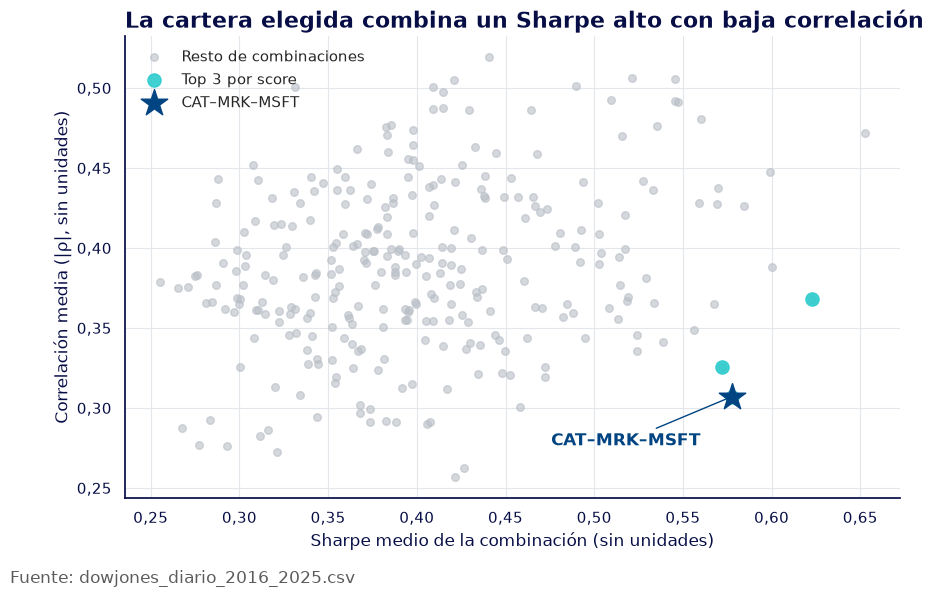

PosixPath('Graficos/dispersion_combinaciones.png')

In [21]:
seleccion = ranking.loc[1, 'combinacion'].split('–')
print('Acciones seleccionadas (1.ª del ranking):', seleccion)
assert sorted(seleccion) == sorted(cartera), 'La selección calculada no coincide con la cartera del notebook'

nuestra = ranking[ranking['combinacion'] == 'CAT–MRK–MSFT']
posicion = nuestra.index[0]
print('Posición de CAT–MRK–MSFT:', posicion, 'de', len(ranking))

top3 = ranking.head(3)

fig, ax = plt.subplots()
ax.scatter(ranking['sharpe_medio'], ranking['corr_media'], color=gris, s=30, alpha=0.6, label='Resto de combinaciones')
ax.scatter(top3['sharpe_medio'], top3['corr_media'], color=BBVA['agua'], s=90, alpha=0.9, label='Top 3 por score')
ax.scatter(nuestra['sharpe_medio'], nuestra['corr_media'], color=BBVA['principal'], marker='*', s=400, label='CAT–MRK–MSFT')

ax.annotate('CAT–MRK–MSFT', (nuestra['sharpe_medio'].iloc[0], nuestra['corr_media'].iloc[0]),
            xytext=(-130, -35), textcoords='offset points', fontsize=12, fontweight='bold', color=BBVA['principal'],
            arrowprops=dict(arrowstyle='-', color=BBVA['principal']))

ax.set_title('La cartera elegida combina un Sharpe alto con baja correlación')
ax.set_xlabel('Sharpe medio de la combinación (sin unidades)')
ax.set_ylabel('Correlación media (|ρ|, sin unidades)')
ax.xaxis.set_major_formatter(lambda v, _: fmt_es(v, 2))
ax.yaxis.set_major_formatter(lambda v, _: fmt_es(v, 2))
ax.legend()
cerrar_grafico(fig, 'dispersion_combinaciones', fuente=fuente_texto, ajustar_titulos=False)

## Paso 8. Frontera eficiente de la cartera

In [22]:
mu_activos = dias * retornos[cartera].mean().values
cov_activos = dias * retornos[cartera].cov().values

rng = np.random.default_rng(42)
n_carteras = 10000
filas = []
for i in range(n_carteras):
    pesos = rng.dirichlet(np.ones(3))
    rent = pesos @ mu_activos
    vol = np.sqrt(pesos @ cov_activos @ pesos)
    filas.append(list(pesos) + [rent, vol, (rent - tasa_libre) / vol])

sim = pd.DataFrame(filas, columns=cartera + ['rent', 'vol', 'sharpe'])

i_max_sharpe = sim['sharpe'].idxmax()
i_min_vol = sim['vol'].idxmin()

pesos_iguales = np.ones(3) / 3
rent_iguales = pesos_iguales @ mu_activos
vol_iguales = np.sqrt(pesos_iguales @ cov_activos @ pesos_iguales)
sharpe_iguales = (rent_iguales - tasa_libre) / vol_iguales

resumen = sim.loc[[i_max_sharpe, i_min_vol]].copy()
resumen.index = ['Máximo Sharpe', 'Mínimo riesgo']
resumen.loc['Pesos iguales'] = list(pesos_iguales) + [rent_iguales, vol_iguales, sharpe_iguales]

sim_ord = sim.sort_values('vol')
frontera = sim_ord[sim_ord['rent'] >= sim_ord['rent'].cummax()]

resumen.round(4)

,CAT,MRK,MSFT,rent,vol,sharpe
Máximo Sharpe,0.3753,0.0132,0.6115,0.2147,0.2346,0.8727
Mínimo riesgo,0.1832,0.5322,0.2846,0.1409,0.1877,0.6974
Pesos iguales,0.3333,0.3333,0.3333,0.1689,0.1966,0.8079


Guardado: Graficos/frontera_eficiente_cartera.png


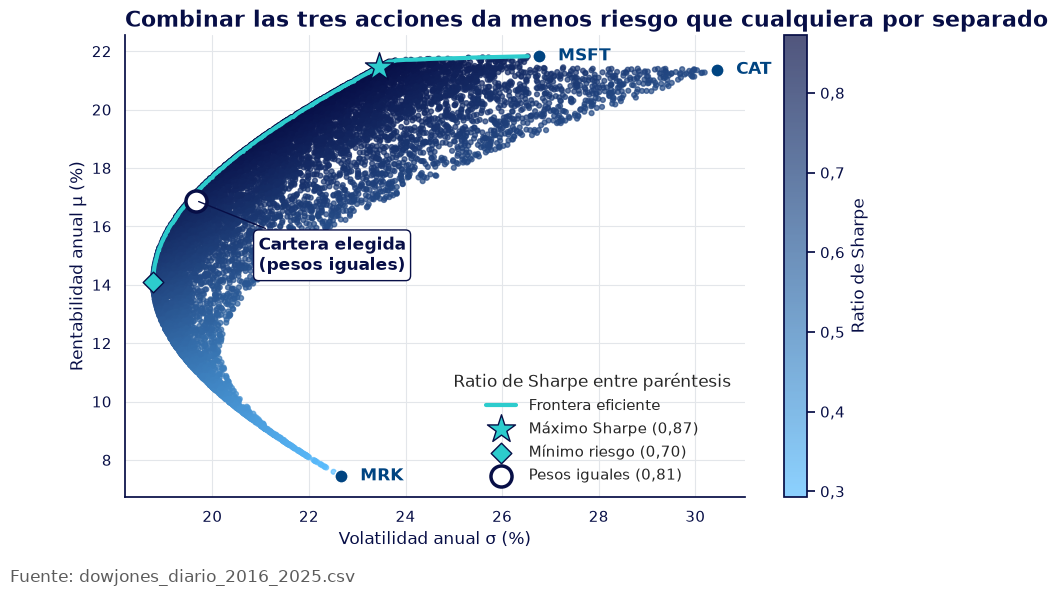

PosixPath('Graficos/frontera_eficiente_cartera.png')

In [23]:
escala_sec = LinearSegmentedColormap.from_list('bbva_sec', [BBVA['cielo'], BBVA['marino']])

fig, ax = plt.subplots()
puntos = ax.scatter(sim['vol'] * 100, sim['rent'] * 100, c=sim['sharpe'], cmap=escala_sec, s=12, alpha=0.7)
ax.plot(frontera['vol'] * 100, frontera['rent'] * 100, color=BBVA['agua'], linewidth=3, label='Frontera eficiente')
ax.scatter(sim.loc[i_max_sharpe, 'vol'] * 100, sim.loc[i_max_sharpe, 'rent'] * 100, color=BBVA['agua'],
           marker='*', s=450, edgecolor=BBVA['marino'], zorder=5,
           label='Máximo Sharpe (' + fmt_es(sim.loc[i_max_sharpe, 'sharpe'], 2) + ')')
ax.scatter(sim.loc[i_min_vol, 'vol'] * 100, sim.loc[i_min_vol, 'rent'] * 100, color=BBVA['agua'],
           marker='D', s=110, edgecolor=BBVA['marino'], zorder=5,
           label='Mínimo riesgo (' + fmt_es(sim.loc[i_min_vol, 'sharpe'], 2) + ')')

ax.scatter(vol_iguales * 100, rent_iguales * 100, color=BBVA['blanco'], marker='o', s=230, edgecolor=BBVA['marino'],
           linewidth=2.5, zorder=6, label='Pesos iguales (' + fmt_es(sharpe_iguales, 2) + ')')
ax.annotate('Cartera elegida\n(pesos iguales)', (vol_iguales * 100, rent_iguales * 100), xytext=(45, -50),
            textcoords='offset points', fontsize=12, fontweight='bold', color=BBVA['marino'],
            bbox=dict(boxstyle='round', fc=BBVA['blanco'], ec=BBVA['marino']),
            arrowprops=dict(arrowstyle='-', color=BBVA['marino']), zorder=7)

sigma_activos = np.sqrt(np.diag(cov_activos))
for i in range(3):
    ax.scatter(sigma_activos[i] * 100, mu_activos[i] * 100, color=BBVA['principal'], s=90, edgecolor='white', zorder=5)
    ax.text(sigma_activos[i] * 100 + 0.4, mu_activos[i] * 100, cartera[i], fontweight='bold', fontsize=12,
            color=BBVA['principal'], va='center')

barra = fig.colorbar(puntos, ax=ax, label='Ratio de Sharpe')
barra.ax.yaxis.set_major_formatter(lambda v, _: fmt_es(v, 1))
ax.set_title('Combinar las tres acciones da menos riesgo que cualquiera por separado')
ax.set_xlabel('Volatilidad anual σ (%)')
ax.set_ylabel('Rentabilidad anual μ (%)')
ax.xaxis.set_major_formatter(lambda v, _: fmt_es(v))
ax.yaxis.set_major_formatter(lambda v, _: fmt_es(v))
ax.legend(title='Ratio de Sharpe entre paréntesis', loc='lower right')
cerrar_grafico(fig, 'frontera_eficiente_cartera', fuente=fuente_texto, ajustar_titulos=False)

## Parámetros para Montecarlo

In [24]:
vector_sigma = metricas.loc[cartera, 'sigma'].values
matriz_rho = correlacion.loc[cartera, cartera].values

assert np.allclose(matriz_rho, matriz_rho.T), 'rho no es simétrica'
print('rho es simétrica')

# Si la matriz no fuese definida positiva, esta línea daría error
np.linalg.cholesky(matriz_rho)
print('Cholesky OK: rho es definida positiva')

parametros = {
    'tickers': cartera,
    'sigma': [vector_sigma.round(6).tolist()],
    'rho': matriz_rho.round(6).tolist(),
    'periodo': {'inicio': str(retornos.index.min().date()), 'fin': str(retornos.index.max().date())},
}

with open('outputs/parametros_montecarlo.json', 'w', encoding='utf-8') as archivo:
    json.dump(parametros, archivo, indent=2, ensure_ascii=False)
parametros

rho es simétrica
Cholesky OK: rho es definida positiva


{'tickers': ['CAT', 'MRK', 'MSFT'],
 'sigma': [[0.304449, 0.226614, 0.267572]],
 'rho': [[1.0, 0.249833, 0.394764],
  [0.249833, 1.0, 0.276564],
  [0.394764, 0.276564, 1.0]],
 'periodo': {'inicio': '2016-01-05', 'fin': '2025-12-31'}}

## Conclusión: ¿vale CAT–MRK–MSFT?

**Sí, vale.** Es la mejor de las 295 combinaciones válidas según el score (0,270; Sharpe medio 0,58; correlación media 0,31).

**Tesis**
1. ✅ μ > 0 y Sharpe > 0 en los tres: CAT 21,4 % (SR 0,67), MSFT 21,8 % (SR 0,78), MRK 7,4 % (SR 0,28).
2. ✅ Todos los pares cumplen |ρ| < 0,6 (CAT–MRK 0,25; CAT–MSFT 0,39; MRK–MSFT 0,28). ❌ El ideal < 0,3 se cumple en dos de tres pares, pero no en CAT–MSFT (0,39).
3. ✅ CAT y MSFT rinden mucho más que MRK.
4. ✅ MRK es la menos volátil (22,7 %, frente a 26,8 % de MSFT y 30,4 % de CAT).

**Puntos débiles**
- La correlación móvil a 252 días supera el límite de 0,6 en los tres pares en algún periodo (máximos: CAT–MRK 0,61; CAT–MSFT 0,70; MRK–MSFT 0,71), probablemente en épocas de estrés. La diversificación es peor justo cuando más se necesita.
- El ranking se basa en el pasado 2016-2025. MSFT y CAT tuvieron una racha excepcional y pueden no repetirla.
- CAT es la más volátil (30,4 %), lo que sube el σ que entra en Montecarlo.

**Alternativas.** La segunda (CAT–MCD–MSFT, score 0,255) y la tercera (CAT–MSFT–PG, 0,247) quedan muy cerca. La diferencia con la primera es pequeña (0,015 y 0,023), así que MRK, MCD o PG son casi intercambiables como pieza defensiva.

**Recomendación:** mantener CAT–MRK–MSFT. Gana en el ranking, cumple todos los criterios obligatorios y tiene tres sectores distintos (Industrial, Salud y Tecnología). Hay que tener presente que MRK, con su perfil defensivo, aporta la estabilidad de la cartera.

**Justificación de las tres acciones**
- **Criterios aplicados a las 26 acciones** (tabla `metricas_acciones.csv`): exclusión cualitativa y motivo, serie completa, C1 (μ > 0), C2 (σ), C3 (Sharpe > 0) y C4 (correlación media y máxima con el resto). Pasan todos los filtros individuales 16 acciones; después se evalúan todas las ternas de sectores distintos con |ρ| < 0,6 (295 combinaciones).
- **MSFT** (Tecnología): el mayor Sharpe de las acciones elegibles (0,78) y μ = 21,8 %.
- **CAT** (Industrial): segundo mayor Sharpe elegible (0,67) y μ = 21,4 %, con una correlación baja con MRK (0,25).
- **MRK** (Salud): activo defensivo, con la menor volatilidad de los tres (22,7 %) y la menor correlación con los otros dos (0,25 y 0,28).
- **Reproducibilidad:** el script no usa azar. Con el mismo CSV, la 1.ª combinación del ranking es siempre CAT–MRK–MSFT, y el paso 7 lo comprueba con una aserción.
- **Limitación:** "gran capitalización" y "negocio maduro" no se pueden calcular con este dataset (no incluye capitalización); se dan por cumplidos por pertenecer al Dow Jones.